# QE021: Messages on a Graph

**Belief propagation: the decoder of modern communication, a cousin of the cavity method in statistical physics, and the
workhorse (with repairs) for quantum LDPC codes.**

Every phone call, Wi-Fi packet and fibre-optic link is protected by codes whose decoder passes **messages** along a
sparse graph: each bit tells its checks what it believes, each check replies, and after a few rounds the beliefs settle.
This is **belief propagation (BP)**. Physicists know the same equations as the **Bethe–Peierls approximation** or the
**cavity method**, used for magnets and spin glasses, and the analogy is exact enough that decoding has phase
transitions: below a critical noise level decoding succeeds, above it the messages get stuck.

This exercise follows BP from classical codes to quantum ones:

* **Section 1:** Tanner graphs, erasures and the peeling decoder, simulated on codes with up to 8,000 bits.
* **Part A (one exact answer, Euler-style):** the BP threshold of the (3,6)-regular LDPC ensemble.
* **Part B1:** the optimal (MAP) threshold from a Maxwell equal-area construction, as in a liquid–gas transition.
* **Part B2:** spatial coupling: a seed at the boundary launches a decoding **wave** that lifts BP up to the optimal
  threshold.
* **Part B3:** quantum codes: why BP gets confused by degeneracy ("split beliefs") on the surface code.
* **Part B4:** decimation: freezing the most confident qubit and rerunning, which breaks the tie.
* **Part B5:** one learnable weight: the simplest "neural" BP.
* **Animation:** the decoding wave sweeping through a spatially coupled chain, next to an uncoupled chain that stays stuck.

### Words used in this notebook

| term | meaning |
|---|---|
| **parity check** | a rule that a group of bits must add up to an even number |
| **LDPC code** | low-density parity-check code: every check touches few bits, every bit sits in few checks |
| **Tanner graph** | the bipartite graph of bits (variable nodes) and checks (check nodes) |
| **(3,6)-regular** | every bit is in 3 checks, every check has 6 bits; the code rate is $1 - 3/6 = 1/2$ |
| **erasure channel (BEC)** | each bit is either received perfectly or lost ("erased") with probability ε |
| **peeling decoder** | repeatedly find a check with exactly one lost bit, and fill it in |
| **belief propagation (BP)** | iterative message passing that estimates each bit's probability |
| **density evolution** | the equation tracking the fraction of unresolved messages in an infinitely large code |
| **threshold** | the noise level where decoding switches from succeeding to failing, like a phase transition |
| **MAP decoding** | optimal decoding, choosing the most probable codeword; usually too slow to run |
| **spatial coupling** | chaining many copies of a code together with overlapping checks, fixed at the ends |
| **syndrome** | the list of failed checks, the only information a quantum decoder gets |
| **degeneracy** | in quantum codes, different errors can be equally good corrections; classical BP was not designed for this |
| **decimation** | fixing one variable to its most likely value and running BP again |
| **min-sum, normalisation α** | a cheaper version of BP; α scales the check messages and can be learned |
| **random seed** | fixes the random draws so every run gives the same numbers |

*Report version: the code is hidden; figures, tables and the animation are the results of the full computation.*

## 1. Erasures and peeling

On the erasure channel each bit arrives intact or is marked "lost". A check with **exactly one** lost bit fixes that
bit: it must make the check even. Filling it in may leave another check with one lost bit, and so on. This is the
**peeling decoder**, and on the erasure channel it is exactly what BP does.

We build random (3,6)-regular codes (each bit in 3 checks, each check on 6 bits, rate 1/2) by randomly wiring 3 sockets
per bit to 6 sockets per check, erase each bit with probability ε, and peel. The information-theoretic limit for a rate-1/2
code is ε = 1/2.

peeled 1500 random codes in 2 s


## Part A: the BP threshold of the (3,6) ensemble

For an infinitely long random code the graph looks locally like a tree, and the probability $x$ that a message from a
bit to a check is still "lost" after $t$ rounds obeys **density evolution**:

$$x_{t+1} = \varepsilon\,\big(1 - (1 - x_t)^{5}\big)^{2}.$$

(A bit stays lost if its channel value was erased and each of its 2 other checks has at least one other lost bit
among its 5 others.) Decoding succeeds if $x_t \to 0$. That fails as soon as a nonzero fixed point appears, so the
threshold is

$$\varepsilon_\text{BP} = \min_{0 < x \le 1} \frac{x}{\big(1 - (1 - x)^{5}\big)^{2}} .$$

**Task:** compute $\varepsilon_\text{BP}$ and report $A = \lfloor 10^{10}\,\varepsilon_\text{BP} \rfloor$.

*Check:* run density evolution itself just below and just above the threshold, and bisect on whether it reaches zero.

threshold from the minimum: ε_BP = 0.429439814419  (stuck messages at threshold: x* = 0.260571)


check, bisection on density evolution: threshold between 0.429439814 and 0.429439814

ANSWER  A = 4294398144


The bisection agrees to all nine digits shown; it slows down right at the threshold because density evolution crawls through
the near-fixed point, just like the critical slowing down of a physical system at a transition.

Compare with the finite codes from Section 1:

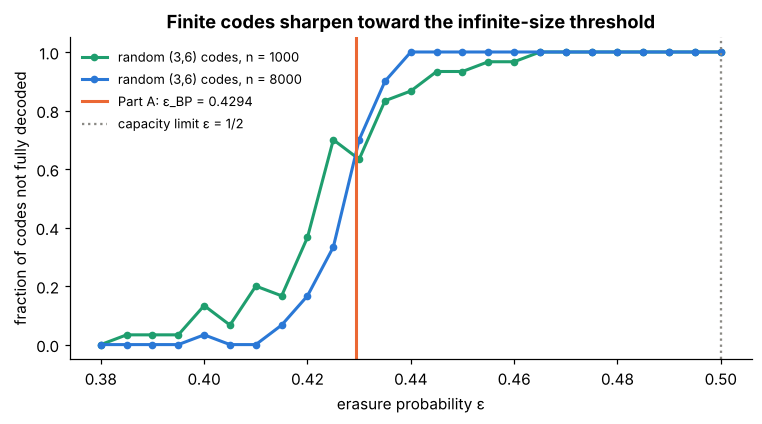

Longer codes switch more sharply, and the switch sits at the threshold computed in Part A. Below it, peeling recovers
everything; above it, a finite fraction of bits stays stuck.

## Part B1: the optimal threshold, by an equal-area rule

BP is not optimal. The best possible (MAP) decoder succeeds up to a higher threshold, $\varepsilon_\text{MAP}$. For the
erasure channel it follows from the **area theorem**: draw the "EXIT curve" (how much a bit still doesn't know, as a
function of ε) along all fixed points of density evolution, including the unstable ones, and cut it vertically so the
area under the kept part equals the code rate. This is the same move as **Maxwell's equal-area construction** for the
van der Waals liquid–gas transition, where an S-shaped curve of metastable states is replaced by a vertical jump.

Parametrised by the fixed point $x$: $\;\varepsilon(x) = x / (1-(1-x)^5)^2$, $\;h(x) = (1-(1-x)^5)^3$.

ε_MAP = 0.48815088   (fixed point x = 0.432263)
gap to capacity: BP loses 0.0706, MAP only 0.0118


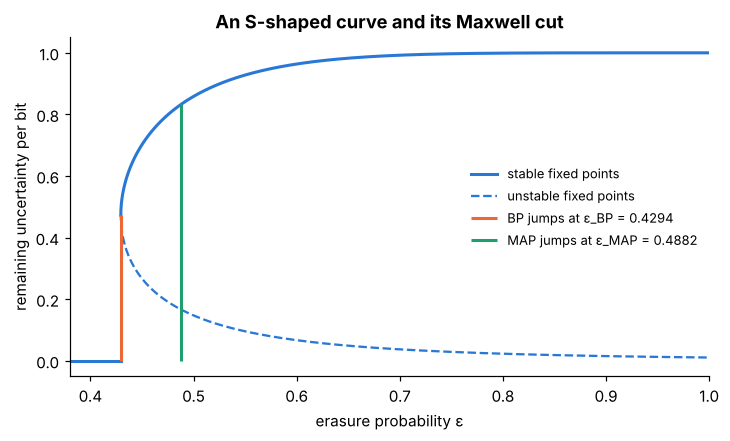

BP jumps at the end of the metastable branch (the **spinodal**). MAP jumps where the two areas balance (the
**coexistence point**). Between $0.4294$ and $0.4882$, the "decoded" state is the true equilibrium but BP is stuck in a
metastable phase, like supercooled water that has not frozen yet.

## Part B2: spatial coupling, a decoding wave

Supercooled water freezes when it touches a seed crystal, and the ice front then sweeps through. **Spatially coupled
codes** do the same for decoding. Place $L$ copies of the code along a line, let each check connect bits from $w$
neighbouring positions, and make the ends easy (no unknown bits beyond them). Density evolution for position $i$:

$$x_i^{t+1} = \varepsilon\,\Big(\frac1w\sum_{j=0}^{w-1}\Big[1 - \Big(1 - \frac1w\sum_{k=0}^{w-1} x_{i+j-k}^{t}\Big)^{5}\Big]\Big)^{2}.$$

The boundaries decode first, and a **front** moves inward at a steady speed. The striking result (Kudekar, Richardson
and Urbanke, 2011) is **threshold saturation**: the coupled BP threshold rises to the MAP threshold.

,uncoupled code: stuck fraction,coupled chain: max stuck fraction,coupled iterations
ε,,,
0.440000,0.327,1.0e-19,108
0.460000,0.379,8.1e-20,211
0.470000,0.399,5.5e-21,339
0.480000,0.418,4.7e-21,765
0.485000,0.427,6.3e-22,1950
0.490000,0.435,4.4e-01,1062


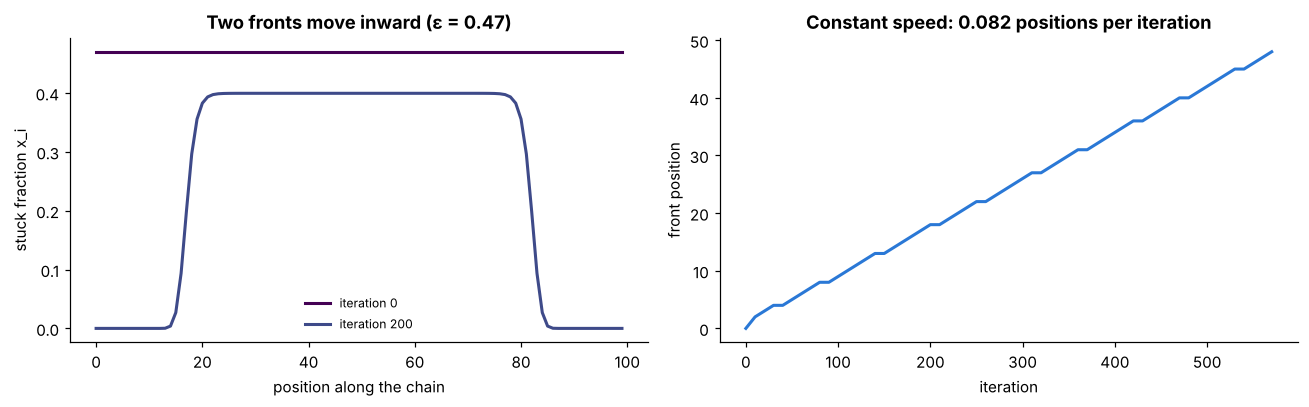

At ε = 0.47 the uncoupled code is stuck with a large fraction of bits unknown, while the coupled chain decodes
completely: the fronts start at the fixed ends and move at a constant speed, exactly like a travelling wave in a
reaction–diffusion system. Just below $\varepsilon_\text{MAP}$ (0.485) the wave still gets through, more slowly; just
above it (0.49) the stuck phase is the stable one and the wave cannot advance. The price is a slight rate loss at the
ends of the chain and a longer code.

## Animation: the decoding wave

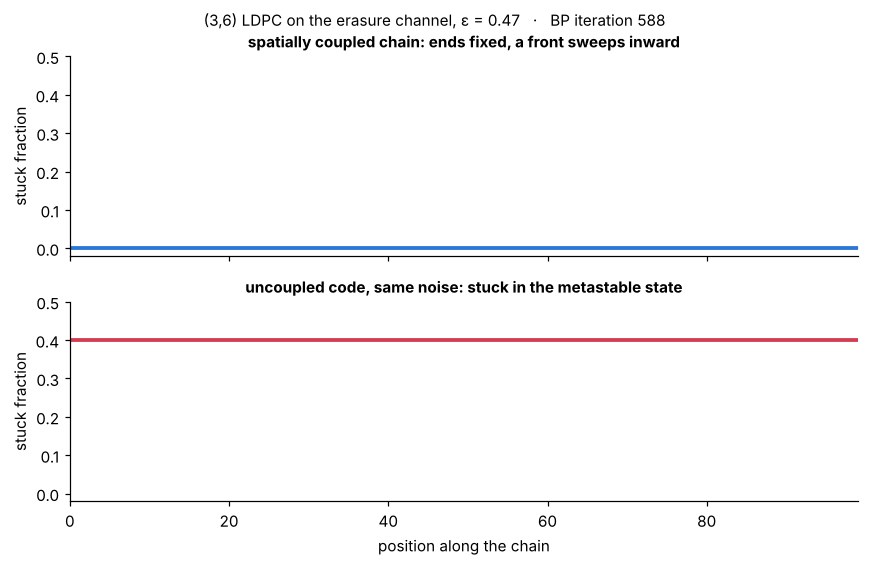

saved qe021_decoding_wave.gif (8 s): coupled chain ends at 3.6e-21, uncoupled at 0.399


**The animation** (embedded, so it plays on GitHub without running anything):

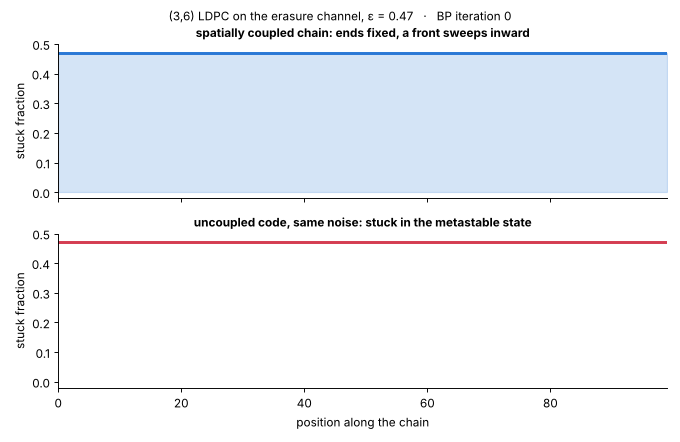

## Part B3: quantum codes and split beliefs

A quantum decoder never sees the error, only the **syndrome** $s = He$. Syndrome BP is the same message passing with
one twist: each check's message is sign-flipped if that check fired. We use the **surface code**, built here as the
hypergraph product of two repetition codes, under independent bit flips with probability $p$ (code capacity). Decoding
fails if the decoder's correction, combined with the error, is a logical operator.

The difficulty is **degeneracy**. On the surface code, many different error patterns have the same syndrome and are
equally good corrections. BP estimates each qubit separately, and when several corrections are about equally likely
it shares the probability among them: no qubit's belief crosses 1/2, so the qubit-by-qubit hard decision explains none
of the fired checks (sometimes the messages oscillate instead of settling). Physicists recognise **frustration** and
an unbroken symmetry.

surface code d = 5: n = 41 qubits, 20 checks for bit flips, k = 1
weight-2 errors on which BP does not converge: 94 of 820


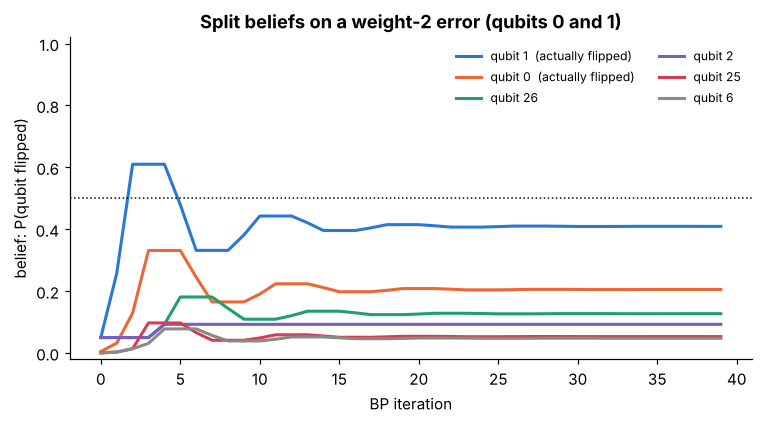

BP settles, but the two qubits that were actually flipped end with beliefs well below 1/2, and the rest of the
probability is spread over neighbouring qubits that offer equivalent explanations. The hard decision flips nothing, the
syndrome is not explained, and BP reports failure even though a weight-2 correction exists. This is the generic failure
of plain BP on quantum codes: it found the right *neighbourhood* but cannot commit to one of the symmetric choices.

## Part B4: break the tie, decimation

The cure from statistical physics is to apply a tiny field that picks one of the symmetric states. **Decimation** does
this: if BP has not converged, take the qubit that BP considers **most likely to be flipped**, commit that flip (and
update the syndrome), pin the qubit, and run BP again on the smaller problem. Each freeze removes some of the symmetry. Variants of this idea,
including guiding the choice by BP itself or learning it, are an active topic for decoding quantum LDPC codes.

the stuck weight-2 error: decimation converges = True, correction weight 6, logical error = False


simulated in 49 s (600 shots per point)


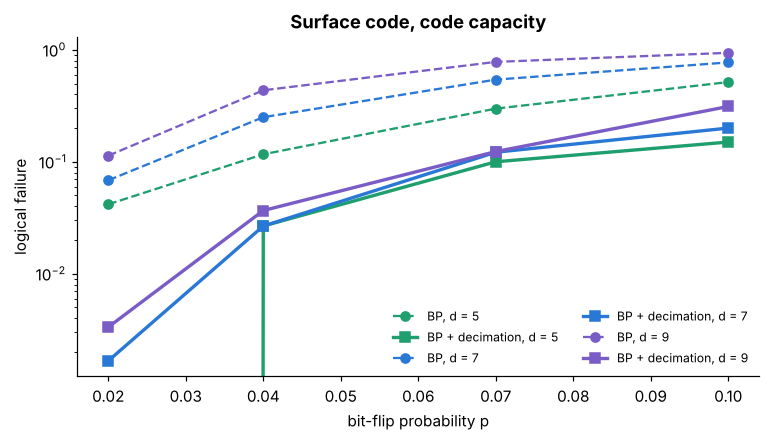

BP                     BP + decimation                    
d            5         7         9               5         7         9
p                                                                     
0.02  0.041667  0.068333  0.113333        0.000000  0.001667  0.003333
0.04  0.116667  0.250000  0.435000        0.026667  0.026667  0.036667
0.07  0.298333  0.541667  0.780000        0.100000  0.121667  0.123333
0.10  0.515000  0.771667  0.940000        0.150000  0.200000  0.311667

Plain BP gets **worse** as the code grows (more places for split beliefs), so it has no threshold on the surface code.
Decimation cuts the failure rate by a factor of about 3 to 40, depending on size and noise. But in this range this simple
version does **not yet** show larger codes doing clearly better, the signature of a decoder below threshold. Closing
that gap is what refined methods (BP with ordered-statistics post-processing, guided or learned decimation) are for.
Decimation also costs extra BP runs on the hard cases, and that latency is what hardware-oriented decoder research
fights with.

## Part B5: one learnable weight

Min-sum is a cheap approximation to BP that overestimates check messages; a scale factor α < 1 compensates. **Neural
BP** generalises this: unroll the iterations into layers of a network and learn a weight for every edge and iteration
from data, keeping the structure of the physical decoding problem (a "physics-based" network). Here we learn the single
global weight by scanning it, with plain BP on the $d = 5$ surface code at $p = 0.03$ (2,000 shots per point).

scanned in 3 s: best α = 0.9, failure 0.069 against 0.075 at α = 1


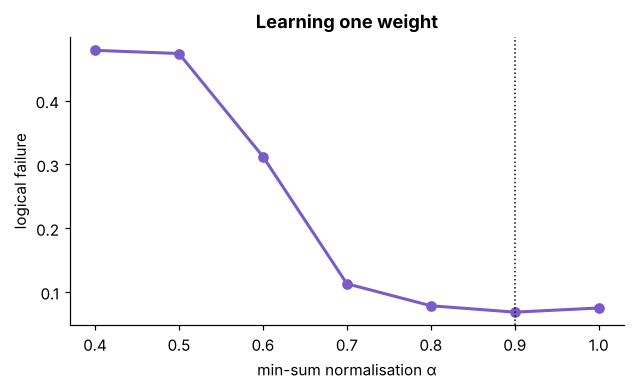

Too small an α is disastrous, because it starves the messages. The best value here, α = 0.9, beats plain α = 1 only
slightly (within about two standard errors of the 2,000-shot estimate). Learning many weights (per edge, per iteration), learning
which qubit to decimate, or learning the whole message update are the next steps up the same ladder; they cannot remove
the degeneracy problem, but they can make the repair cheaper.

## Honest limits

* **Code capacity only** in Parts B3–B5: perfect syndromes and independent bit flips. Real decoders must handle noisy
  measurements over many rounds.
* **Surface codes are a hard case for BP** but also have excellent dedicated decoders (matching, union-find). BP-based
  decoders earn their keep on high-rate quantum LDPC codes, where those dedicated decoders do not apply.
* **The decimation here is a simple textbook version**; published guided-decimation and BP+OSD decoders are more
  refined. Shot counts are modest, so the quantum curves carry sampling error of tens of percent at the lowest rates.

## Conclusions

1. **Exact answer.** The (3,6)-regular LDPC ensemble decodes by BP up to
   $\varepsilon_\text{BP} = 0.4294398144$, so $A = 4294398144$; random codes with 8,000 bits switch there sharply.
2. **Decoding has phase transitions.** The MAP threshold 0.4882 follows from an equal-area rule, the same construction
   as for a liquid–gas transition; between the two thresholds BP is stuck in a metastable state.
3. **Coupling nucleates decoding.** A spatially coupled chain decodes up to the MAP threshold through a wave moving at
   constant speed.
4. **Degeneracy frustrates BP.** On the surface code, equally good corrections split the beliefs and plain BP gets worse
   with size.
5. **Breaking the symmetry helps.** Decimation cuts failures several-fold or more; making larger codes clearly better
   needs more refined decoders. The single learned weight must at least avoid starving the messages; its fine-tuning gain here is small.

**Try it yourself:** decode the coupled chain with finite-length random codes, try other degree pairs $(l, r)$, apply
syndrome BP to a hypergraph-product code of a good classical LDPC code, or learn one α per iteration.

### Further reading

* T. Richardson, R. Urbanke, *Modern Coding Theory*, Cambridge University Press (2008).
* M. Mézard, A. Montanari, *Information, Physics, and Computation*, Oxford University Press (2009).
* S. Kudekar, T. Richardson, R. Urbanke, *Threshold saturation via spatial coupling: why convolutional LDPC ensembles
  perform so well over the BEC*, IEEE Trans. Inf. Theory 57, 803 (2011).
* J. S. Yedidia, W. T. Freeman, Y. Weiss, *Constructing free-energy approximations and generalized belief propagation
  algorithms*, IEEE Trans. Inf. Theory 51, 2282 (2005).
* D. Poulin, Y. Chung, *On the iterative decoding of sparse quantum codes*, Quantum Inf. Comput. 8, 987 (2008).
* E. Nachmani, Y. Be'ery, D. Burshtein, *Learning to decode linear codes using deep learning*, Allerton (2016).
* P. Panteleev, G. Kalachev, *Degenerate quantum LDPC codes with good finite length performance*, Quantum 5, 585 (2021).
* H. Yao et al., *Belief propagation decoding of quantum LDPC codes with guided decimation*, ISIT (2024).